<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 4. Modellierung

Dieses Notebook führt die Modellierungspipeline für ein Pairs-Trading-Setup aus:

- Laden des bereinigten Wide-Preispanels (`prices_wide_cleaned.csv`)
- Zeitbasierter Split in Train/Holdout (tagweise)
- Pair-Selektion (Korrelation → optional Cointegration-Filter)
- Feature-Panel (symbolbasierte technische Features) und Zusammenbau eines Pair-Datensatzes
- Label-Konstruktion (Mean-Reversion innerhalb `HORIZON`, intraday-sicher)
- Training/Kalibrierung von Klassifikationsmodellen und Holdout-Reporting
- Backtests: Baseline (fixer Entry) und ML-basierte dynamische Entry-Policy (inkl. Kosten)


In [1]:
# Zelle 1
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    precision_recall_curve,
)

from pairs_trading import data_io as io
from pairs_trading.eda.correlation import correlation_analysis
from pairs_trading.eda.cointegration import (
    compute_daily_cointegration,
    compute_pair_stats,
    rank_pairs,
)

from pairs_trading.features import build_feature_panel
from pairs_trading.features.technical import log_returns


In [2]:
# Zelle 2
HOLDOUT_FRACTION_DAYS = 0.20

CORR_METHOD = "pearson"
STRONG_THRESHOLD = 0.97
TOP_N_CORR_PAIRS = 200
USE_COINTEGRATION = True
COINT_P_THRESH = 0.05
MIN_OBS_PER_DAY_COINT = 60
TOP_N_FINAL_PAIRS = 20

HEDGE_WINDOW = 300
ZSCORE_WINDOW = 300
HORIZON = 30
Z_ENTRY = 2.0
REVERT_TO = 0.5

SMA_WINDOWS = (20,)
EMA_SPANS = (20,)
RSI_WINDOWS = (14,)
ROC_WINDOWS = (10,)
VOL_WINDOWS = (20,)

BB_WINDOWS = (20,)
SPREAD_RSI_W = 14
SPREAD_ROC_W = 10
SPREAD_VOL_W = 20

COST_PER_SIDE = 0.0001

USE_DYNAMIC_ENTRY_POLICY = True
P_ENTRY = 0.60
Z_MIN = 1.25

RANDOM_STATE = 42

In [3]:
# Zelle 3
df = io.load_preprocessed_data(
    data_dir="Daten",
    basename="market_data_cleaned"
)


[Preprocessed Data Load]
Pfad: Daten\market_data_cleaned.parquet

[Preprocessed Data]
Shape: (7490150, 7)
Spalten: ['datetime', 'symbol', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
                   datetime symbol        open        high         low  \
0 2025-11-07 14:30:00+00:00      A  146.520004  147.119995  145.729996   
1 2025-11-07 14:31:00+00:00      A         NaN         NaN         NaN   
2 2025-11-07 14:32:00+00:00      A  146.089996  146.089996  146.089996   
3 2025-11-07 14:33:00+00:00      A         NaN         NaN         NaN   
4 2025-11-07 14:34:00+00:00      A  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  


In [4]:
df["datetime"] = pd.to_datetime(df["datetime"], errors="raise")

if "close_filled" not in df.columns:
    raise ValueError("Erwartete Spalte 'close_filled' nicht gefunden")

prices_wide = (
    df
    .pivot_table(
        index="datetime",
        columns="symbol",
        values="close_filled",
        aggfunc="last",
    )
    .sort_index()
)

prices_wide = (
    prices_wide
    .apply(pd.to_numeric, errors="coerce")
    .dropna(axis=1, how="all")
)

log_prices = np.log(prices_wide)

prices_wide.iloc[:3, :3]

symbol,A,AAPL,ABBV
datetime,,,
2025-11-07 14:30:00+00:00,145.729996,268.674988,218.285004
2025-11-07 14:31:00+00:00,145.909996,268.309998,218.244995
2025-11-07 14:32:00+00:00,146.089996,267.420013,218.764999


In [5]:
# Zelle 4 — Log-Preise (aus dem geladenen Wide-Panel) + kurzer Sanity-Check
# Erwartung: prices_wide kommt aus Zelle 3 (Datetime-Index, Spalten=Symbole, Werte=Close)

prices_wide = prices_wide.sort_index()

log_prices = np.log(prices_wide)

print("prices_wide shape:", prices_wide.shape)
print("log_prices shape:  ", log_prices.shape)
print("Start:", prices_wide.index.min(), "| Ende:", prices_wide.index.max())

prices_wide.iloc[:3, :3]


prices_wide shape: (15638, 479)
log_prices shape:   (15638, 479)
Start: 2025-11-07 14:30:00+00:00 | Ende: 2026-01-09 21:00:00+00:00


symbol,A,AAPL,ABBV
datetime,,,
2025-11-07 14:30:00+00:00,145.729996,268.674988,218.285004
2025-11-07 14:31:00+00:00,145.909996,268.309998,218.244995
2025-11-07 14:32:00+00:00,146.089996,267.420013,218.764999


In [6]:
# Zelle 5 — Train/Holdout Tage bestimmen (für Pair-Selection und Modellierung)
df["date"] = df["datetime"].dt.floor("D")
all_days = np.array(sorted(df["date"].unique()))
n_holdout = int(max(1, round(HOLDOUT_FRACTION_DAYS * len(all_days))))
cutoff_day = all_days[-n_holdout]  # Holdout startet ab cutoff_day

train_mask = df["date"] < cutoff_day
holdout_mask = df["date"] >= cutoff_day

print("Train-Tage:", int(df.loc[train_mask, "date"].nunique()))
print("Holdout-Tage:", int(df.loc[holdout_mask, "date"].nunique()))
print("Holdout ab:", cutoff_day)

# Log-Preise für Pair-Selection nur Train (verhindert Data Snooping)
log_prices_train = log_prices.loc[log_prices.index.floor("D") < cutoff_day].copy()


Train-Tage: 32
Holdout-Tage: 8
Holdout ab: 2025-12-29 00:00:00+00:00


In [7]:
# Zelle 6 — Pair-Auswahl (Korrelation → optional Cointegration → Ranking nach CONSISTENCY)

corr_out = correlation_analysis(
    prices_wide=log_prices_train,
    method=CORR_METHOD,
    strong_threshold=STRONG_THRESHOLD,
    plot=False,
    title=None,
)

strong_pairs = corr_out["strong_pairs"].copy()

if strong_pairs.empty:
    raise ValueError("Keine starken Paare gefunden. STRONG_THRESHOLD reduzieren.")

# --- Top-N nach Korrelation ---
pairs_corr = (
    strong_pairs
    .rename(columns={
        "symbol_1": "symbol1",
        "symbol_2": "symbol2",
        "correlation": "corr",
    })
    .head(TOP_N_CORR_PAIRS)
    .reset_index(drop=True)
)

pairs_sel = pairs_corr.copy()

# --- Optional: Cointegration-Filter + Ranking ---
if USE_COINTEGRATION:
    pairs_list = list(
        pairs_sel[["symbol1", "symbol2"]]
        .itertuples(index=False, name=None)
    )

    daily_coint = compute_daily_cointegration(
        log_prices_train,
        pairs_list,
        min_obs_per_day=MIN_OBS_PER_DAY_COINT,
        sort_index=True,
        sort_symbols_in_pair=True,
        verbose=False,
    )

    if not daily_coint.empty:
        stats = compute_pair_stats(
            daily_coint,
            p_thresh=COINT_P_THRESH,
        )

        ranked_df, _ = rank_pairs(stats)

        ranked = (
            ranked_df
            .reset_index()
            .rename(columns={
                "level_0": "symbol1",
                "level_1": "symbol2",
            })
        )

        # --- Optionaler p-Filter (kein Ranking danach!) ---
        #if "mean_p" in ranked.columns:
        #    ranked = ranked[ranked["mean_p"] <= COINT_P_THRESH]

        if ranked.empty:
            raise ValueError("Nach Cointegration-Filter keine Paare übrig.")

        if "consistency" not in ranked.columns:
            raise KeyError(
                "Spalte 'consistency' fehlt. "
                "Prüfe compute_pair_stats() / rank_pairs()."
            )

        # --- FINAL: Ranking ausschließlich nach CONSISTENCY ---
        pairs_sel = (
            ranked
            .sort_values("consistency", ascending=False)
            .reset_index(drop=True)
        )

# --- Finale Auswahl ---
pairs_final_df = pairs_sel.head(TOP_N_FINAL_PAIRS).copy()

PAIRS = list(
    pairs_final_df[["symbol1", "symbol2"]]
    .itertuples(index=False, name=None)
)

print(f"Finale Anzahl Pairs: {len(PAIRS)}")
print("Beispiele:", PAIRS[:10])


Finale Anzahl Pairs: 20
Beispiele: [('KEY', 'LUV'), ('CTSH', 'KEY'), ('CTSH', 'HBAN'), ('AEP', 'CMS'), ('CTSH', 'USB'), ('CTSH', 'PNC'), ('CTSH', 'LUV'), ('MTB', 'PNC'), ('GM', 'USB'), ('LUV', 'RF')]


In [8]:
# ============================================================
# ZELLE 7 — Feature Panel (train-only gebaut; tz-konform)
# ============================================================

# --- Helper: tz-aware -> UTC -> tz-naive (oder tz-naive bleibt tz-naive) ---
def _to_utc_naive_ts(x) -> pd.Timestamp:
    ts = pd.to_datetime(x)
    if ts.tzinfo is not None:
        ts = ts.tz_convert("UTC").tz_localize(None)
    return ts

def _to_utc_naive_index(idx: pd.DatetimeIndex) -> pd.DatetimeIndex:
    idx = pd.to_datetime(idx)
    # Falls tz-aware: nach UTC konvertieren, dann tz entfernen
    if getattr(idx, "tz", None) is not None:
        idx = idx.tz_convert("UTC").tz_localize(None)
    return idx

# --- cutoff_day robust tz-naiv in UTC ---
cutoff_day = _to_utc_naive_ts(cutoff_day).floor("D")

# --- log_prices Index robust tz-naiv in UTC ---
# (wichtig: du musst denselben Index später auch in build_pair_block / merges verwenden)
log_prices = log_prices.copy()
log_prices.index = _to_utc_naive_index(log_prices.index)

# Train-Index bestimmen (bis VOR cutoff_day) — jetzt tz-kompatibel
train_idx = log_prices.index.floor("D") < cutoff_day

# 1) Features strikt auf TRAIN bauen
feature_panel_train = build_feature_panel(
    log_prices=log_prices.loc[train_idx].copy(),
    pairs=PAIRS,
    rsi_window=SPREAD_RSI_W,      # z.B. 14
    z_window=ZSCORE_WINDOW,       # MUSS zu späterer zscore-Alias passen
    vol_window=SPREAD_VOL_W,      # z.B. 20
)

# 2) Full-Panel bauen, damit Holdout-Zeiten Features haben,
#    aber Train-Zeiten mit train-only überschreiben (kein Train-Leakage)
feature_panel_full = build_feature_panel(
    log_prices=log_prices.copy(),
    pairs=PAIRS,
    rsi_window=SPREAD_RSI_W,
    z_window=ZSCORE_WINDOW,
    vol_window=SPREAD_VOL_W,
)

# Kombinieren: Train aus train-only, Holdout aus full
feature_panel = feature_panel_full.copy()
feature_panel.loc[feature_panel.index.floor("D") < cutoff_day] = feature_panel_train

print("Feature-Panel gebaut (tz-naiv UTC; Train: train-only, Holdout: full).")
print("cutoff_day:", cutoff_day)
print("log_prices index tz:", getattr(log_prices.index, "tz", None))
print("Shape:", feature_panel.shape)
print("MultiIndex columns:", isinstance(feature_panel.columns, pd.MultiIndex))
print("Feature examples:", sorted(set(feature_panel.columns.get_level_values(0)))[:15])


Feature-Panel gebaut (tz-naiv UTC; Train: train-only, Holdout: full).
cutoff_day: 2025-12-29 00:00:00
log_prices index tz: None
Shape: (15339, 100)
MultiIndex columns: True
Feature examples: ['RETURN', 'RSI_14', 'VOL_20', 'Z_300', 'spread']


In [9]:
# ============================================================
# ZELLE X — Helper-Funktionen für build_pair_block
# ============================================================

def _rolling_beta(lp1: pd.Series, lp2: pd.Series, window: int) -> pd.Series:
    """
    Rolling OLS Beta für Regression lp1 ~ beta * lp2 (ohne Intercept).
    beta_t = Cov(lp2, lp1) / Var(lp2) im Rolling-Window.

    Robust gegen NaNs; gibt NaN zurück, solange window nicht voll ist oder Var=0.
    """
    x = pd.to_numeric(lp2, errors="coerce")
    y = pd.to_numeric(lp1, errors="coerce")

    cov_xy = x.rolling(window).cov(y)
    var_x = x.rolling(window).var()

    beta = cov_xy / var_x.replace(0.0, np.nan)
    return beta


def _rolling_zscore(x: pd.Series, window: int) -> pd.Series:
    """
    Rolling Z-Score: (x - rolling_mean) / rolling_std
    ddof=0 für stabilere std in kleinen Fenstern.
    """
    s = pd.to_numeric(x, errors="coerce")
    m = s.rolling(window).mean()
    sd = s.rolling(window).std(ddof=0).replace(0.0, np.nan)
    return (s - m) / sd


In [10]:
# ============================================================
# ZELLE Y — Helper: flatten_features_for_pair (kompatibel zu build_feature_panel)
# ============================================================
def flatten_features_for_pair(feature_panel: pd.DataFrame, s1: str, s2: str) -> pd.DataFrame:
    """
    Nimmt das MultiIndex-Feature-Panel aus pairs_trading.features.build_feature_panel
    und extrahiert die Features für ein spezifisches Pair (s1, s2) als "flaches" DF.

    Erwartetes Format feature_panel:
      - Index: DatetimeIndex
      - Columns: MultiIndex (level 0 = feature, level 1 = pair_name "S1_S2")

    Output:
      - Index: DatetimeIndex
      - Columns: einzelne Feature-Spalten (z.B. "RSI_14", "Z_300", "VOL_20", "RETURN")
    """
    if not isinstance(feature_panel.columns, pd.MultiIndex) or feature_panel.columns.nlevels != 2:
        raise TypeError("feature_panel muss MultiIndex-Spalten mit 2 Levels haben: (feature, pair_name).")

    pair_name = f"{s1}_{s2}"
    pair_name_rev = f"{s2}_{s1}"

    lvl_pair = feature_panel.columns.get_level_values(1)

    if pair_name in set(lvl_pair):
        sub = feature_panel.xs(pair_name, axis=1, level=1, drop_level=True)
    elif pair_name_rev in set(lvl_pair):
        sub = feature_panel.xs(pair_name_rev, axis=1, level=1, drop_level=True)
    else:
        # Pair nicht im Panel -> leeres DF zurückgeben (build_pair_block skippt dann via merge-NAs)
        return pd.DataFrame(index=feature_panel.index)

    # sub hat jetzt Spalten = Feature-Namen (level 0)
    # Sicherstellen, dass es ein DataFrame ist
    if isinstance(sub, pd.Series):
        sub = sub.to_frame()

    return sub.sort_index()


In [11]:
# ============================================================
# FIXED ZELLE 8 — build_pair_block mit intraday-sicherem Label
# ============================================================

def build_pair_block(
    * ,
    log_prices_all: pd.DataFrame = None,
    log_prices: pd.DataFrame = None,
    feature_panel_all: pd.DataFrame,
    s1: str,
    s2: str,
    hedge_window: int = 60,
    zscore_window: int = 60,
    horizon: int = 20,
    z_entry: float = 2.0,
    revert_to: float = 0.5,
) -> pd.DataFrame:
    """
    Kontrakt:
      - datetime, date (Timestamp floor('D')), pair, symbol1, symbol2
      - lp1, lp2, beta, spread, zscore, z_abs
      - y_revert (nur bei Entry-Events, sonst NaN)
      - plus: Package-Features (ohne semantische Kollisionen)
    """
    lp_all = log_prices_all if log_prices_all is not None else log_prices
    if lp_all is None:
        raise TypeError("Du musst log_prices_all oder log_prices übergeben.")

    if s1 not in lp_all.columns or s2 not in lp_all.columns:
        return pd.DataFrame()

    lp = lp_all[[s1, s2]].dropna()
    if lp.empty:
        return pd.DataFrame()

    out = pd.DataFrame(index=lp.index)
    out["lp1"] = lp[s1]
    out["lp2"] = lp[s2]

    # Baseline-Hedge & Spread
    out["beta"] = _rolling_beta(out["lp1"], out["lp2"], hedge_window)
    out["spread"] = out["lp1"] - out["beta"] * out["lp2"]

    out["zscore"] = _rolling_zscore(out["spread"], zscore_window)
    out["z_abs"] = out["zscore"].abs()

    # --- Zeitspalten früh setzen (für intraday-safe shift) ---
    out = out.reset_index().rename(columns={"index": "datetime"})
    out["datetime"] = pd.to_datetime(out["datetime"], errors="raise")

    # tz-aware -> UTC -> tz-naive (falls jemals relevant)
    if getattr(out["datetime"].dt, "tz", None) is not None:
        out["datetime"] = out["datetime"].dt.tz_convert("UTC").dt.tz_localize(None)

    out["date"] = out["datetime"].dt.floor("D")

    # --- Intraday-sicheres Label: shift NUR innerhalb des Tages ---
    out = out.sort_values("datetime").reset_index(drop=True)
    out["z_fwd"] = out.groupby("date")["zscore"].shift(-horizon)
    out["is_horizon_safe"] = out["z_fwd"].notna()

    entry = (out["z_abs"] >= z_entry) & out["is_horizon_safe"]
    out["y_revert"] = np.where(entry, (out["z_fwd"].abs() <= revert_to).astype(float), np.nan)

    # Metadaten
    out["pair"] = f"{s1}__{s2}"
    out["symbol1"] = s1
    out["symbol2"] = s2

    # Package-Features joinen (ohne semantische Spread-Kollision)
    fp_pair = flatten_features_for_pair(feature_panel_all, s1, s2)
    if "spread" in fp_pair.columns:
        fp_pair = fp_pair.drop(columns=["spread"], errors="ignore")

    fp_pair = fp_pair.reset_index().rename(columns={"index": "datetime"})
    fp_pair["datetime"] = pd.to_datetime(fp_pair["datetime"], errors="raise")

    if getattr(fp_pair["datetime"].dt, "tz", None) is not None:
        fp_pair["datetime"] = fp_pair["datetime"].dt.tz_convert("UTC").dt.tz_localize(None)

    out = out.merge(fp_pair, on="datetime", how="left")

    # Final cleaning: Baseline-Spalten + Label-Sicherheit
    out = out.dropna(subset=["beta", "spread", "zscore"])

    # Hilfsspalten entfernen (optional, aber sauber)
    out = out.drop(columns=["z_fwd", "is_horizon_safe"], errors="ignore")

    return out

In [12]:
# ZELLE 9 — ML-Dataset bauen (alle Pairs) — robuste Signatur

frames = []
for (s1, s2) in PAIRS:
    dfp = build_pair_block(
        log_prices_all=log_prices,          # oder: log_prices=log_prices
        feature_panel_all=feature_panel,
        s1=s1,
        s2=s2,
        hedge_window=HEDGE_WINDOW,
        zscore_window=ZSCORE_WINDOW,
        horizon=HORIZON,
        z_entry=Z_ENTRY,
        revert_to=REVERT_TO,
    )
    if not dfp.empty:
        frames.append(dfp)

ml_df = pd.concat(frames, ignore_index=True)
display(ml_df.head())
print("Rows:", len(ml_df), "| Cols:", ml_df.shape[1])
print("Columns sample:", list(ml_df.columns)[:20])


,datetime,lp1,lp2,beta,spread,zscore,z_abs,date,y_revert,pair,symbol1,symbol2,RETURN,RSI_14,VOL_20,Z_300
0,2025-11-10 17:57:00,2.903891,3.486151,0.478706,1.235051,0.852469,0.852469,2025-11-10,NaN,KEY__LUV,KEY,LUV,-0.000135,64.970886,0.000545,2.186614
1,2025-11-10 17:58:00,2.903343,3.485845,0.479302,1.232571,0.861034,0.861034,2025-11-10,NaN,KEY__LUV,KEY,LUV,-0.000343,60.116926,0.000548,2.093979
2,2025-11-10 17:59:00,2.903069,3.486304,0.480503,1.227888,0.862566,0.862566,2025-11-10,NaN,KEY__LUV,KEY,LUV,-0.000582,54.366623,0.000565,1.945533
3,2025-11-10 18:00:00,2.903343,3.485998,0.481329,1.225432,0.872452,0.872452,2025-11-10,NaN,KEY__LUV,KEY,LUV,0.000479,56.249360,0.000542,2.060639
4,2025-11-10 18:01:00,2.903069,3.486656,0.482243,1.221653,0.878215,0.878215,2025-11-10,NaN,KEY__LUV,KEY,LUV,-0.000715,45.719551,0.000513,1.877708


Rows: 300794 | Cols: 16
Columns sample: ['datetime', 'lp1', 'lp2', 'beta', 'spread', 'zscore', 'z_abs', 'date', 'y_revert', 'pair', 'symbol1', 'symbol2', 'RETURN', 'RSI_14', 'VOL_20', 'Z_300']


In [13]:
# ============================================================
# Zelle 10
# CLEAN SPLIT + FEATURES: EINMALIG und konsistent
# ============================================================

def _ensure_time_contract(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.copy()

    if "datetime" not in df.columns:
        raise KeyError("ml_df braucht eine Spalte 'datetime' (kommt aus build_pair_block).")

    df["datetime"] = pd.to_datetime(df["datetime"], errors="raise")

    # tz-aware -> UTC -> tz-naive (stabil für Vergleiche / sort)
    if getattr(df["datetime"].dt, "tz", None) is not None:
        df["datetime"] = df["datetime"].dt.tz_convert("UTC").dt.tz_localize(None)

    # date als Tages-Timestamp (nicht python date-object)
    df["date"] = df["datetime"].dt.floor("D")

    return df.sort_values(["datetime", "pair"]).reset_index(drop=True)


ml_df = _ensure_time_contract(ml_df)

# cutoff_day robust normalisieren (kommt bei dir aus Zelle 5 als numpy datetime64 / Timestamp)
cutoff_day = pd.to_datetime(cutoff_day)
if cutoff_day.tzinfo is not None:
    cutoff_day = cutoff_day.tz_convert("UTC").tz_localize(None)
cutoff_day = cutoff_day.floor("D")

# Target-Spalte robust bestimmen + vereinheitlichen
target_candidates = ["y_revert", "target", "y"]
target_col = next((c for c in target_candidates if c in ml_df.columns), None)
if target_col is None:
    raise KeyError(f"Keine Target-Spalte gefunden. Erwartet eine von: {target_candidates}")

if target_col != "y_revert":
    ml_df["y_revert"] = ml_df[target_col]
target_col = "y_revert"

# Nur Zeilen mit Label
ml_df = ml_df.dropna(subset=[target_col]).copy()

# Non-Feature-Spalten (Contract + Baseline-Spalten ausschließen)
non_feature = {
    target_col,
    "datetime", "date",
    "pair", "symbol1", "symbol2",
    "lp1", "lp2", "beta", "spread", "zscore", "z_abs",
}

feature_cols = [c for c in ml_df.columns if c not in non_feature]
feature_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(ml_df[c])]

if not feature_cols:
    raise ValueError(
        "Keine numerischen Feature-Spalten gefunden. "
        "Prüfe Feature-Join (Zelle 8) und ob du dort Features droppst."
    )

# Split exakt nach cutoff_day (wie Pair-Selection!)
train = ml_df.loc[ml_df["date"] < cutoff_day].copy()
hold  = ml_df.loc[ml_df["date"] >= cutoff_day].copy()

if train.empty or hold.empty:
    raise ValueError(
        f"Train/Holdout leer. Prüfe cutoff_day={cutoff_day} und date-range in ml_df."
    )

X_train = train[feature_cols].copy()
y_train = train[target_col].astype(int).copy()

X_hold = hold[feature_cols].copy()
y_hold = hold[target_col].astype(int).copy()

print("cutoff_day:", cutoff_day)
print("train:", train.shape, "| hold:", hold.shape)
print("n_features:", len(feature_cols))
print("train datetime:", train["datetime"].min(), "->", train["datetime"].max())
print("hold  datetime:", hold["datetime"].min(), "->", hold["datetime"].max())


cutoff_day: 2025-12-29 00:00:00
train: (39981, 16) | hold: (9723, 16)
n_features: 4
train datetime: 2025-11-10 17:57:00 -> 2025-12-26 20:30:00
hold  datetime: 2025-12-29 14:30:00 -> 2026-01-09 20:29:00


In [14]:
# ZELLE 11 — Baseline (fixes Z_ENTRY) + PnL-Logik inkl. Transaktionskosten (intraday-sicher)

def backtest_baseline_fixed_entry(
    df_all: pd.DataFrame,
    *,
    horizon: int,
    z_entry: float,
    cost_per_side: float,
) -> pd.DataFrame:
    """
    Baseline-Backtest:
      - Entry: |z| >= z_entry
      - Exit: nach horizon Bars (intraday-sicher via groupby(date).shift)
      - Direction: z>0 => short spread, z<0 => long spread
      - PnL = direction * (spread_exit - spread_entry)
      - Kosten: 2 * cost_per_side (Roundtrip) nur wenn entry=True
    """
    d = df_all.copy()
    d = d.sort_values(["pair", "datetime"]).reset_index(drop=True)

    d["spread_exit"] = d.groupby(["pair", "date"])["spread"].shift(-horizon)
    d["is_horizon_safe"] = d["spread_exit"].notna()

    d["entry"] = (d["zscore"].abs() >= z_entry) & d["is_horizon_safe"]

    # z>0 => short spread => direction = -1 ; z<0 => long => +1
    d["direction"] = np.where(d["zscore"] > 0, -1.0, +1.0)

    # --- KORREKTUR: gross_pnl nur bei entry zählen ---
    d["gross_pnl"] = np.where(
        d["entry"],
        d["direction"] * (d["spread_exit"] - d["spread"]),
        0.0,
    )

    d["cost"] = np.where(d["entry"], 2.0 * cost_per_side, 0.0)
    d["net_pnl"] = np.where(d["entry"], d["gross_pnl"] - d["cost"], 0.0)

    pnl_ts = (
        d.groupby("datetime")[["gross_pnl", "net_pnl", "entry"]]
         .sum()
         .rename(columns={"entry": "n_trades"})
         .reset_index()
         .sort_values("datetime")
    )
    pnl_ts["cum_net_pnl"] = pnl_ts["net_pnl"].cumsum()
    pnl_ts["cum_gross_pnl"] = pnl_ts["gross_pnl"].cumsum()
    return pnl_ts


# --- ausführen (Holdout) ---
df_holdout = ml_df.loc[ml_df["date"] >= cutoff_day].copy()

baseline_all = backtest_baseline_fixed_entry(
    df_all=df_holdout,
    horizon=HORIZON,
    z_entry=Z_ENTRY,
    cost_per_side=COST_PER_SIDE,
)

display(baseline_all.tail())
print("Baseline Holdout — last cum gross pnl:", float(baseline_all["cum_gross_pnl"].iloc[-1]))
print("Baseline Holdout — last cum net pnl  :", float(baseline_all["cum_net_pnl"].iloc[-1]))


,datetime,gross_pnl,net_pnl,n_trades,cum_net_pnl,cum_gross_pnl
2126,2026-01-09 20:25:00,0.0,0.0,0,2389.890085,2391.006285
2127,2026-01-09 20:26:00,0.0,0.0,0,2389.890085,2391.006285
2128,2026-01-09 20:27:00,0.0,0.0,0,2389.890085,2391.006285
2129,2026-01-09 20:28:00,0.0,0.0,0,2389.890085,2391.006285
2130,2026-01-09 20:29:00,0.0,0.0,0,2389.890085,2391.006285


Baseline Holdout — last cum gross pnl: 2391.0062849450014
Baseline Holdout — last cum net pnl  : 2389.8900849449974


In [15]:
# ============================================================
# ZELLE 12 — Modelle + CV auf TRAIN, dann echtes HOLDOUT Reporting
# ============================================================

pos = float(y_train.sum())
neg = float(len(y_train) - y_train.sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0

models = {
    "LogReg": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="saga",
            penalty="l2",
            max_iter=5000,
            tol=1e-3,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ]),
    "XGB": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),  # optional; für XGB meist nicht nötig, aber ok
        ("clf", XGBClassifier(
            n_estimators=600,
            learning_rate=0.03,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            scale_pos_weight=scale_pos_weight,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ]),
    "RF": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            max_depth=None,
            min_samples_leaf=5,
        )),
    ]),
}

# Kalibrierung (probabilities fürs Trading)
calib_cv = TimeSeriesSplit(n_splits=3)
pipelines = {
    name: CalibratedClassifierCV(
        estimator=pipe,
        method="sigmoid",
        cv=calib_cv,
        n_jobs=-1,
    )
    for name, pipe in models.items()
}

# Outer CV (nur auf train)
outer_cv = TimeSeriesSplit(n_splits=3)

cv_rows = []
for name, model in pipelines.items():
    aucs, aps = [], []
    for tr_idx, va_idx in outer_cv.split(X_train):
        m = clone(model)
        m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        p = m.predict_proba(X_train.iloc[va_idx])[:, 1]
        aucs.append(roc_auc_score(y_train.iloc[va_idx], p))
        aps.append(average_precision_score(y_train.iloc[va_idx], p))

    cv_rows.append({
        "model": name,
        "cv_auc_mean": float(np.mean(aucs)),
        "cv_auc_std": float(np.std(aucs)),
        "cv_ap_mean": float(np.mean(aps)),
        "cv_ap_std": float(np.std(aps)),
    })

cv_df = pd.DataFrame(cv_rows).sort_values("cv_auc_mean", ascending=False).reset_index(drop=True)
print("CV-Ergebnisse (Train):")
display(cv_df)

best_model_name = cv_df.loc[0, "model"]
best_model = pipelines[best_model_name]

best_model.fit(X_train, y_train)
p_hold = best_model.predict_proba(X_hold)[:, 1]

print(f"Bestes Modell (nach CV AUC): {best_model_name}")
print("Holdout AUC:", float(roc_auc_score(y_hold, p_hold)))
print("Holdout AP :", float(average_precision_score(y_hold, p_hold)))


CV-Ergebnisse (Train):


,model,cv_auc_mean,cv_auc_std,cv_ap_mean,cv_ap_std
0,XGB,0.535715,0.015168,0.024330,0.005164
1,RF,0.508184,0.072757,0.025054,0.009621
2,LogReg,0.471455,0.030065,0.019756,0.004071


Bestes Modell (nach CV AUC): XGB
Holdout AUC: 0.49726514052679155
Holdout AP : 0.03414746028810112


Holdout — Positivrate (Base rate): 0.031163
Holdout — p_hold min/max: 0.018 / 0.030544
Holdout — Average Precision (AP): 0.034147 | AP / Base rate: 1.096


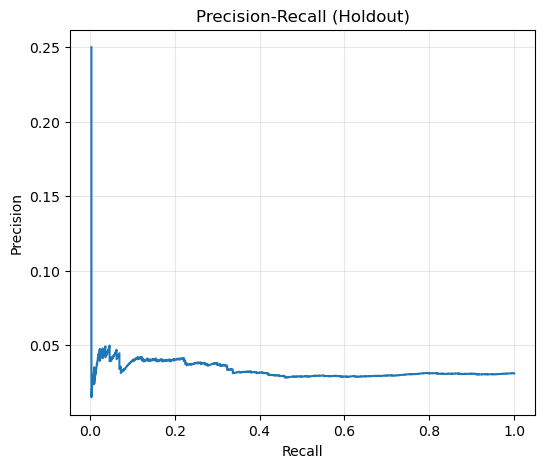


Klassifikationsbericht (Holdout, Schwelle = 99%-Quantil aus TRAIN-Scores, thr=0.027885):
              precision    recall  f1-score   support

           0      0.969     0.996     0.982      9420
           1      0.023     0.003     0.006       303

    accuracy                          0.965      9723
   macro avg      0.496     0.499     0.494      9723
weighted avg      0.939     0.965     0.952      9723


Klassifikationsbericht (Holdout, F1-optimale Schwelle aus TRAIN, thr=0.027039):
              precision    recall  f1-score   support

           0      0.969     0.990     0.980      9420
           1      0.032     0.010     0.015       303

    accuracy                          0.960      9723
   macro avg      0.501     0.500     0.497      9723
weighted avg      0.940     0.960     0.949      9723



In [16]:
# Zelle 13 — Reporting: AP/PR (imbalance-robust) + sinnvolle Schwellenwahl

base_rate = float(np.mean(y_hold))
p_min, p_max = float(np.min(p_hold)), float(np.max(p_hold))
ap = average_precision_score(y_hold, p_hold)

print("Holdout — Positivrate (Base rate):", round(base_rate, 6))
print("Holdout — p_hold min/max:", round(p_min, 6), "/", round(p_max, 6))
print("Holdout — Average Precision (AP):", round(float(ap), 6), "| AP / Base rate:", round(float(ap / base_rate), 3))

prec_h, rec_h, _ = precision_recall_curve(y_hold, p_hold)
mask = rec_h > 0
plt.figure(figsize=(6, 5))
plt.plot(rec_h[mask], prec_h[mask])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall (Holdout)")
plt.grid(True, alpha=0.3)
plt.show()

p_train = best_model.predict_proba(X_train)[:, 1]

q = 0.99
thr_q = float(np.quantile(p_train, q))
y_pred_q = (p_hold >= thr_q).astype(int)

print(f"\nKlassifikationsbericht (Holdout, Schwelle = {q:.0%}-Quantil aus TRAIN-Scores, thr={thr_q:.6f}):")
print(classification_report(y_hold, y_pred_q, digits=3, zero_division=0))

prec_t, rec_t, ths_t = precision_recall_curve(y_train, p_train)
f1_t = 2 * (prec_t * rec_t) / (prec_t + rec_t + 1e-12)
best_idx_t = int(np.nanargmax(f1_t))
thr_f1 = float(ths_t[max(best_idx_t - 1, 0)])
y_pred_f1 = (p_hold >= thr_f1).astype(int)

print(f"\nKlassifikationsbericht (Holdout, F1-optimale Schwelle aus TRAIN, thr={thr_f1:.6f}):")
print(classification_report(y_hold, y_pred_f1, digits=3, zero_division=0))


In [17]:
# %%
# Zelle 14 — Dynamische Entry-Policy (ML) + Backtest inkl. Kosten (PNL BUG FIXED)

def backtest_ml_dynamic_entry(
    df_all: pd.DataFrame,
    model,
    feature_cols: list[str],
    *,
    horizon: int,
    p_entry=None,
    p_entry_quantile=None,
    z_min: float,
    cost_per_side: float,
) -> pd.DataFrame:
    if (p_entry is None) == (p_entry_quantile is None):
        raise ValueError("Gib genau eine der beiden Optionen an: p_entry ODER p_entry_quantile.")

    d = df_all.copy()
    d = d.sort_values(["pair", "datetime"]).reset_index(drop=True)

    d["spread_exit"] = d.groupby(["pair", "date"])["spread"].shift(-horizon)
    d["is_horizon_safe"] = d["spread_exit"].notna()

    X = d[feature_cols]
    d["p_revert"] = model.predict_proba(X)[:, 1]

    if p_entry_quantile is not None:
        d["_p_for_thr"] = d["p_revert"].where(d["is_horizon_safe"])
        d["thr"] = (
            d.groupby("pair", group_keys=False)["_p_for_thr"]
             .apply(lambda s: s.expanding().quantile(p_entry_quantile).shift(1))
        )
        d.drop(columns=["_p_for_thr"], inplace=True)
    else:
        d["thr"] = float(p_entry)

    d["entry"] = (
        d["thr"].notna()
        & (d["p_revert"] >= d["thr"])
        & (d["z_abs"] >= z_min)
        & d["is_horizon_safe"]
    )

    d["direction"] = np.where(d["zscore"] > 0, -1.0, +1.0)

    # --- PNL BUG FIX: gross_pnl nur bei entry zählen ---
    d["gross_pnl"] = np.where(
        d["entry"],
        d["direction"] * (d["spread_exit"] - d["spread"]),
        0.0,
    )

    d["cost"] = np.where(d["entry"], 2.0 * cost_per_side, 0.0)
    d["net_pnl"] = np.where(d["entry"], d["gross_pnl"] - d["cost"], 0.0)

    pnl_ts = (
        d.groupby("datetime")[["gross_pnl", "net_pnl", "entry"]]
         .sum()
         .rename(columns={"entry": "n_trades"})
         .reset_index()
         .sort_values("datetime")
    )

    pnl_ts["cum_net_pnl"] = pnl_ts["net_pnl"].cumsum()
    pnl_ts["cum_gross_pnl"] = pnl_ts["gross_pnl"].cumsum()
    return pnl_ts


if USE_DYNAMIC_ENTRY_POLICY:
    ml_curves = {}

    df_bt = ml_df.loc[ml_df["date"] >= cutoff_day].copy()

    for name, model in pipelines.items():
        model.fit(X_train, y_train)

        curve = backtest_ml_dynamic_entry(
            df_all=df_bt,
            model=model,
            feature_cols=feature_cols,
            horizon=HORIZON,
            p_entry_quantile=0.99,
            z_min=Z_MIN,
            cost_per_side=COST_PER_SIDE,
        )

        if curve is not None and len(curve) > 0:
            ml_curves[name] = curve

    print(f"ML-Policy Backtests fertig. Modelle: {list(ml_curves.keys())}")
else:
    ml_curves = {}


ML-Policy Backtests fertig. Modelle: ['LogReg', 'XGB', 'RF']


Trades (Baseline): 5581


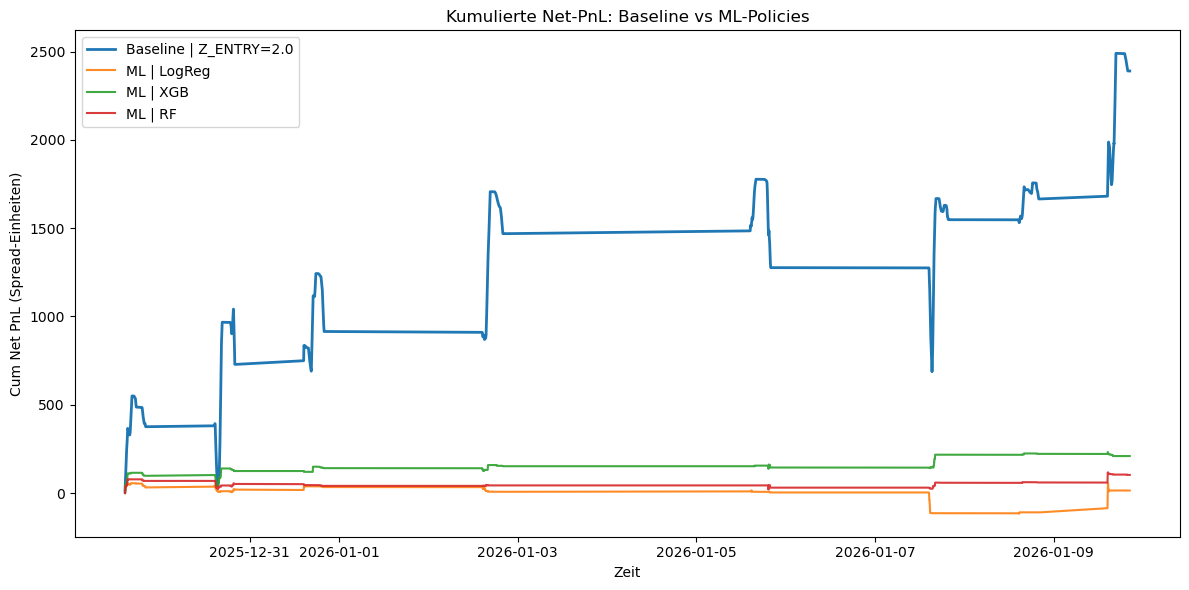

,model,trades,final_cum_net_pnl
0,XGB,230,209.518312
1,RF,163,102.837580
2,LogReg,265,14.375572


In [18]:
# Zelle 15 — Vergleich: Baseline vs alle ML-Policies in einem Plot

plt.figure(figsize=(12, 6))

plt.plot(
    baseline_all["datetime"],
    baseline_all["cum_net_pnl"],
    label=f"Baseline | Z_ENTRY={Z_ENTRY}",
    linewidth=2,
)

print("Trades (Baseline):", int(baseline_all["n_trades"].sum()))

summary_rows = []

if USE_DYNAMIC_ENTRY_POLICY and len(ml_curves) > 0:
    for name, curve in ml_curves.items():
        plt.plot(
            curve["datetime"],
            curve["cum_net_pnl"],
            label=f"ML | {name}",
            alpha=0.9,
        )

        trades = int(curve["n_trades"].sum()) if "n_trades" in curve.columns else np.nan
        final_pnl = float(curve["cum_net_pnl"].iloc[-1])

        summary_rows.append({
            "model": name,
            "trades": trades,
            "final_cum_net_pnl": final_pnl,
        })

plt.title("Kumulierte Net-PnL: Baseline vs ML-Policies")
plt.xlabel("Zeit")
plt.ylabel("Cum Net PnL (Spread-Einheiten)")
plt.legend()
plt.tight_layout()
plt.show()

if len(summary_rows) > 0:
    summary_df = (
        pd.DataFrame(summary_rows)
          .sort_values("final_cum_net_pnl", ascending=False)
          .reset_index(drop=True)
    )
    display(summary_df)


<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="04_Explorative_Datenanalyse.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="06_.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
